<a href="https://colab.research.google.com/github/Epsi-Tech/Development-of-AI-Based-Knowledge-Retrieval-Platform-with-Query-Resolution-System/blob/main/python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
1.
# NumPy library, primarily used for fast numerical operations and managing homogeneous multi-dimensional arrays.
# Pandas library, used for data analysis, cleaning, and tabular data manipulation.
# months = np.array(['Jan', 'Feb', ...]): Creates a 1D NumPy array of string labels representing the first six months.
# sales_amounts = np.array([1200, 1500, ...]): Creates a 1D array of integers representing sales figures for each corresponding month.
# store_id = np.repeat(101, 6): Generates an array repeating the integer 101 six times ([101, 101, 101, 101, 101, 101]) to represent a single store across all months.
# data_dict = { ... }: Groups the three NumPy arrays into a Python dictionary, where keys will serve as column names and values as column data.
# df_pandas = pd.DataFrame(data_dict): Converts the dictionary into a 2D labeled tabular structure (a DataFrame).
# Each key becomes a column, and the matching array lengths become rows indexed 0 through 5.

import numpy as np
import pandas as pd

# 1. NumPy: Generate large numerical arrays efficiently
months = np.array(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'])
sales_amounts = np.array([1200, 1500, 900, 1800, 2100, 1700])
store_id = np.repeat(101, 6) # Repeats the number 101 six times

# 2. Pandas: Structure, clean, and manipulate tabular data
data_dict = {
    'Month': months,
    'Sales': sales_amounts,
    'StoreID': store_id
}
df_pandas = pd.DataFrame(data_dict)

# Quick Pandas Manipulations
df_pandas['Tax'] = df_pandas['Sales'] * 0.05       # Add a calculated column
high_sales = df_pandas[df_pandas['Sales'] > 1400]  # Filter rows

print("Pandas DataFrame:")
print(df_pandas)


Pandas DataFrame:
  Month  Sales  StoreID    Tax
0   Jan   1200      101   60.0
1   Feb   1500      101   75.0
2   Mar    900      101   45.0
3   Apr   1800      101   90.0
4   May   2100      101  105.0
5   Jun   1700      101   85.0


In [2]:
2.
# Imports the Polars library. By convention, it is abbreviated as pl
# df_polars = pl.DataFrame({ ... }): Converts a standard Python dictionary directly into a 2D tabular structure
# with_columns(...): This method is used to add new columns or overwrite existing ones
# pl.col("Sales") * 0.05: Selects the Sales column and multiplies every value in it by 0.05 (5%).
# .alias("Tax"): Gives this newly calculated column the name "Tax".
# .filter(...): This method filters rows based on a specific condition.
# pl.col("Sales") > 1400: Evaluates each row and keeps only the ones where the Sales figure is strictly greater than 1400.


import polars as pl

# Create a Polars DataFrame (similar dictionary input syntax)
df_polars = pl.DataFrame({
    'Month': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'],
    'Sales': [1200, 1500, 900, 1800, 2100, 1700],
    'StoreID': [101, 101, 101, 101, 101, 101]
})

# Polars uses high-performance expressions for data transformation
df_polars = df_polars.with_columns(
    (pl.col("Sales") * 0.05).alias("Tax")
).filter(
    pl.col("Sales") > 1400
)

print("\nPolars Filtered DataFrame:")
print(df_polars)



Polars Filtered DataFrame:
shape: (4, 4)
┌───────┬───────┬─────────┬───────┐
│ Month ┆ Sales ┆ StoreID ┆ Tax   │
│ ---   ┆ ---   ┆ ---     ┆ ---   │
│ str   ┆ i64   ┆ i64     ┆ f64   │
╞═══════╪═══════╪═════════╪═══════╡
│ Feb   ┆ 1500  ┆ 101     ┆ 75.0  │
│ Apr   ┆ 1800  ┆ 101     ┆ 90.0  │
│ May   ┆ 2100  ┆ 101     ┆ 105.0 │
│ Jun   ┆ 1700  ┆ 101     ┆ 85.0  │
└───────┴───────┴─────────┴───────┘


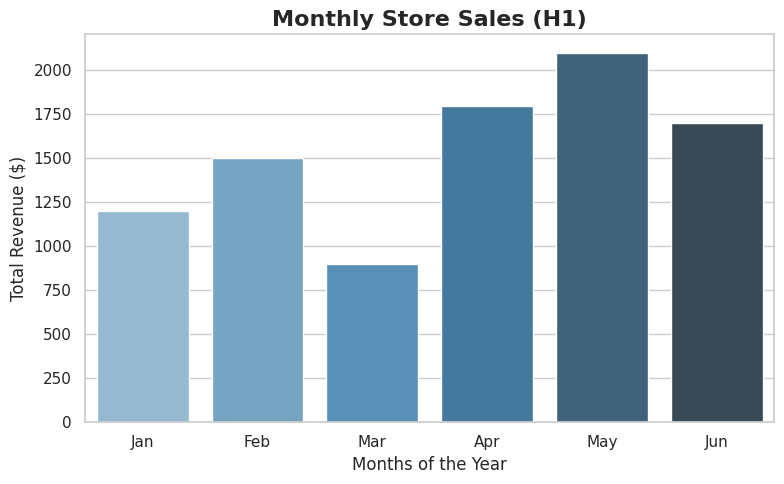

In [3]:
3.
# import matplotlib.pyplot as plt: Loads the primary plotting engine in Python, which manages the underlying figure windows, grid adjustments, and text labels.
# import seaborn as sns: Loads Seaborn, a high-level visualization library built on top of Matplotlib that provides beautiful default styles.
# sns.set_theme(style="whitegrid"): Instantly changes the default gray background to a clean, modern look featuring a white background with subtle horizontal gridlines, making it much easier to read numerical values across the chart.
# fig, ax = plt.subplots(figsize=(8, 5)): Prepares an explicit plotting layout. fig represents the overall window canvas, and ax is the specific chart grid inside it. figsize=(8, 5) sets the chart dimensions to 8 inches wide by 5 inches tall.
# sns.barplot(...): Draws the data from the Pandas DataFrame (df_pandas).
# x='Month', y='Sales': Tells the chart to put the time increments on the horizontal axis and the revenue figures on the vertical axis.
# ax=ax: Explicitly instructs Seaborn to paint this plot onto the specific axes layout we created right above.
# palette='Blues_d', hue='Month', legend=False: Fixes the warning encountered previously. It applies a dark blue-to-light blue gradient palette across the months, satisfies Seaborn's requirement to link those colors to the 'Month' variable (hue), and hides the redundant sidebar color legend.


import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual theme using Seaborn
sns.set_theme(style="whitegrid")

# Initialize a Matplotlib figure and axis layout
fig, ax = plt.subplots(figsize=(8, 5))

# Create a Seaborn barplot using our Pandas data
sns.barplot(x='Month', y='Sales', data=df_pandas, ax=ax, palette='Blues_d', hue='Month', legend=False)


# Customize the chart layout using Matplotlib functions
ax.set_title('Monthly Store Sales (H1)', fontsize=16, fontweight='bold')
ax.set_xlabel('Months of the Year', fontsize=12)
ax.set_ylabel('Total Revenue ($)', fontsize=12)

# Display the final static chart
plt.tight_layout()
plt.show()


In [4]:
4.
# import plotly.express as px: Imports the "Express" module of Plotly. It is designed to create complex, beautiful, and interactive charts with very few lines of code.
# fig = px.bar(...): Initializes a bar chart object using the data provided in the Pandas DataFrame (df_pandas).
#	df_pandas, x='Month', y='Sales': Sets the source data table and maps the horizontal X-axis to months and the vertical Y-axis to sales revenue.
#	title='Interactive Monthly Sales Data': Automatically adds a clean, properly aligned main title at the top left of the graphic.
#	labels={'Sales': 'Revenue ($)', 'Month': 'Timeline'}: Customizes the axis labels on the fly. Plotly automatically renames the axis text and also updates the pop-up boxes (hovers) to use these clean terms instead of raw code column names.
#	text_auto=True: An incredibly convenient feature that automatically calculates and draws the exact data values (e.g., 1200, 1500) right on top of each corresponding bar, eliminating the need to guess by looking at the Y-axis.


import plotly.express as px

# Generate an interactive bar chart using Plotly Express
fig = px.bar(
    df_pandas,
    x='Month',
    y='Sales',
    title='Interactive Monthly Sales Data',
    labels={'Sales': 'Revenue ($)', 'Month': 'Timeline'},
    text_auto=True # Automatically displays values on top of the bars
)

# Render the interactive visual in your browser or notebook
fig.show()


In [5]:
5.
# sqlite3: A built-in Python module that lets you work with SQL databases without needing to install external database software like MySQL or PostgreSQL.
# pd: The pandas library, which is commonly used for data analysis. Note: Although imported here, it is not actually used in this specific snippet.
# connect(':memory:'): Creates a brand-new SQL database directly in RAM instead of saving a file to your hard drive
# cursor(): Creates a cursor object. Think of the cursor as a pointer or a blinking terminal cursor that allows you to execute SQL commands and fetch results
# sales: Contains 4 columns to track daily category performance: date, category, financial revenue (REAL / float), and number of items (INT).
# products: Contains 3 columns to track inventory and reviews: product_name, stock count, and quality rating.

import sqlite3
import pandas as pd

# Create a mock database in memory
conn = sqlite3.connect(':memory:')
cursor = conn.cursor()

# Create tables
cursor.execute("CREATE TABLE sales (date TEXT, category TEXT, revenue REAL, units_sold INT)")
cursor.execute("CREATE TABLE products (product_name TEXT, stock INT, rating REAL)")

# Insert mock rows
sales_data = [
    ('2026-01-01', 'Electronics', 1200.0, 15), ('2026-01-01', 'Clothing', 400.0, 20),
    ('2026-01-02', 'Electronics', 1500.0, 18), ('2026-01-02', 'Clothing', 600.0, 30),
    ('2026-01-03', 'Electronics', 800.0, 10),  ('2026-01-03', 'Clothing', 750.0, 35),
    ('2026-01-04', 'Electronics', 1900.0, 22), ('2026-01-04', 'Clothing', 900.0, 45)
]
product_data = [
    ('Laptop', 45, 4.7), ('Smartphone', 120, 4.5), ('Headphones', 300, 4.2),
    ('Smartwatch', 80, 3.9), ('Tablet', 15, 4.1), ('Charger', 500, 4.6)
]

cursor.executemany("INSERT INTO sales VALUES (?, ?, ?, ?)", sales_data)
cursor.executemany("INSERT INTO products VALUES (?, ?, ?)", product_data)
conn.commit()
print("Database ready!")


Database ready!


In [6]:
6.
# plotly.express (px): A high-level data visualization library. It allows you to create complex, interactive, and beautifully styled charts with just a few lines of code.
# The sales table, groups all matching rows by their category (Electronics and Clothing), and adds up all the values in the revenue column using SUM(revenue).
# pd.read_sql_query(...): This bridges SQL and Python. It runs the query against your in-memory database (conn) and automatically packages the results into a structured Pandas DataFrame (df).
# df, x=..., y=...: Tells Plotly to use your DataFrame, placing the distinct categories on the X-axis and the calculated total revenue on the Y-axis.
# labels: Cleans up the chart labels by renaming the database column total_revenue to a cleaner format: Revenue ($).
# color='category': Assigns a unique color to each individual bar based on its category name.
# template='plotly_white': Applies a clean, minimalist white background theme to the graph.


import plotly.express as px

# SQL Query: Sum up revenue grouped by category
query = """
SELECT category, SUM(revenue) as total_revenue
FROM sales
GROUP BY category
"""
df = pd.read_sql_query(query, conn)

# Plotting
fig = px.bar(df, x='category', y='total_revenue',
             title='Total Revenue by Product Category',
             labels={'total_revenue': 'Revenue ($)', 'category': 'Category'},
             color='category',
             template='plotly_white')
fig.show()


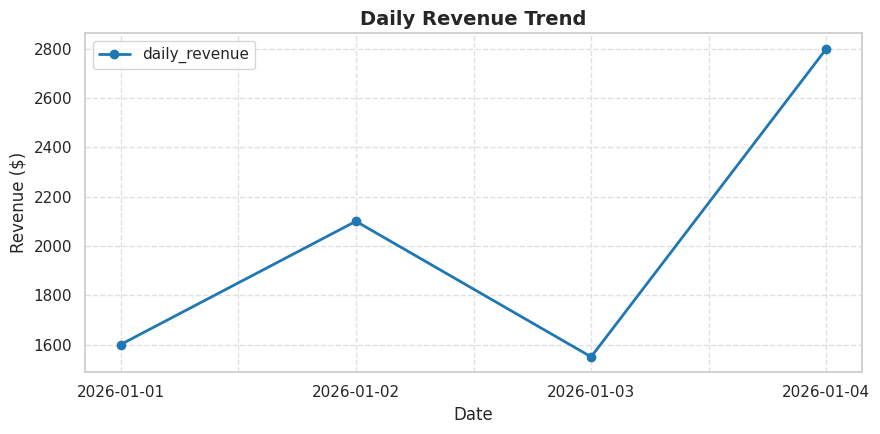

In [7]:
7.
# matplotlib.pyplot (plt): The standard, foundational plotting library in Python. It gives you precise control over every detail of a graph, such as lines, grids, fonts, and spacing
# sales table, merges all transactions that happened on the same day (GROUP BY date), and calculates the overall total for each day (SUM(revenue)).
# ORDER BY date: Essential for time-series charts. This ensures the data rows are sorted chronologically from earliest to latest so the timeline flows correctly left-to-right.
# pd.read_sql_query: Runs the query and saves the results into a new Pandas DataFrame (df).
# Pandas has Matplotlib built directly into it. Instead of writing heavy code, you can call .plot() directly on your DataFrame:
# • kind='line': Specfies a line chart to track trends over time.
# • marker='o': Adds a distinct circular dot at each actual data point along the line.
# • color='#1f77b4': Sets the line to a professional, classic slate blue.
# • figsize=(9, 4.5): Sets the dimensions of the window canvas (9 inches wide by 4.5 inches tall).
# • plt.grid(...): Adds a dashed (--) background grid with 60% opacity (alpha=0.6) to make it easier to read values across the axes.
# • plt.tight_layout(): Automatically shrinks and scales the margins so that labels, text, and titles never get clipped or overlap.


import matplotlib.pyplot as plt

# SQL Query: Get daily revenue totals ordered chronologically
query = """
SELECT date, SUM(revenue) as daily_revenue
FROM sales
GROUP BY date
ORDER BY date
"""
df = pd.read_sql_query(query, conn)

# Plotting directly with Pandas
df.plot(x='date', y='daily_revenue', kind='line', marker='o', color='#1f77b4', figsize=(9, 4.5), linewidth=2)

plt.title('Daily Revenue Trend', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [8]:
8.
# !pip install pyspark -q: This installs the Apache Spark library silently (-q stands for quiet) into your environment.
# SparkSession.builder... initializes your local Spark cluster environment under the application name "EcomJoins".
# The code creates a Python list of tuples (users_data) containing user IDs, names, and tier status.
# The orders_data list tracks transaction data, including an order ID, a foreign key referencing the user, and the purchase amount.
# spark.createDataFrame(): This converts the local Python list into a distributed Spark DataFrame (users_df) using the defined column schemas.

# Install PySpark
!pip install pyspark -q

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, coalesce, lit, sum, count

# Initialize Spark
spark = SparkSession.builder.appName("EcomJoins").getOrCreate()

# 1. Users Dataset (Dimension Table)
users_data = [
    (101, "Amit", "Premium"),
    (102, "Priya", "Free"),
    (103, "Rohan", "Premium"),
    (104, "Sneha", "Free")  # Sneha has placed no orders
]
users_cols = ["user_id", "user_name", "membership"]
users_df = spark.createDataFrame(users_data, schema=users_cols)

# 2. Orders Dataset (Fact Table)
orders_data = [
    (5001, 101, 1200.50),  # Amit's first order
    (5002, 102, 450.00),   # Priya's order
    (5003, 101, 850.25),   # Amit's second order (One-to-Many)
    (5004, 999, 3100.00)   # Order from User 999 (Orphaned row/Data mismatch)
]
orders_cols = ["order_id", "user_fk", "order_amount"]
orders_df = spark.createDataFrame(orders_data, schema=orders_cols)

print("Users DataFrame:")
users_df.show()
print("Orders DataFrame:")
orders_df.show()


Users DataFrame:
+-------+---------+----------+
|user_id|user_name|membership|
+-------+---------+----------+
|    101|     Amit|   Premium|
|    102|    Priya|      Free|
|    103|    Rohan|   Premium|
|    104|    Sneha|      Free|
+-------+---------+----------+

Orders DataFrame:
+--------+-------+------------+
|order_id|user_fk|order_amount|
+--------+-------+------------+
|    5001|    101|      1200.5|
|    5002|    102|       450.0|
|    5003|    101|      850.25|
|    5004|    999|      3100.0|
+--------+-------+------------+



In [9]:
9.
# An Inner Join strictly requires a match in both dataframes. If a row does not find a match on the other side, it is completely dropped from the final result.
# Problem: Generate a report showing the names of customers who have actively placed orders, along with their order IDs and transaction amounts.
# Note: Sneha (no orders) and Order 5004 (invalid user) are excluded.

active_orders = users_df.join(
    orders_df,
    users_df.user_id == orders_df.user_fk,
    how="inner"
).select("user_name", "order_id", "order_amount")

active_orders.show()



+---------+--------+------------+
|user_name|order_id|order_amount|
+---------+--------+------------+
|     Amit|    5001|      1200.5|
|     Amit|    5003|      850.25|
|    Priya|    5002|       450.0|
+---------+--------+------------+



In [10]:
10.
# Concept: Left Join + Group By + Null Handling (coalesce)
# Problem: Calculate the total amount spent by every single registered user. If a user hasn't bought anything yet (like Sneha), display their total spent as 0.00 instead of null.
# This code performs a Left Outer Join followed by a Group By aggregation to calculate the total amount of money spent by every user, including those who haven't placed any orders.
# users_df.join(..., how="left"): This initiates a Left Join. It keeps all rows from the left dataframe (users_df), even if they don't find a matching user_fk in the right dataframe (orders_df).
# .groupBy("user_name", "membership"): This groups the combined dataset by the user's name and tier. Any aggregation that follows will be calculated per unique group.
# .agg(...): This block defines the aggregations to calculate for each group.
# sum("order_amount"): This adds up all the order values for each specific user.


user_spending = (
    users_df.join(orders_df, users_df.user_id == orders_df.user_fk, how="left")
    .groupBy("user_name", "membership")
    .agg(
        coalesce(sum("order_amount"), lit(0.0)).alias("total_spent")
    )
)

user_spending.show()


+---------+----------+-----------+
|user_name|membership|total_spent|
+---------+----------+-----------+
|    Priya|      Free|      450.0|
|    Sneha|      Free|        0.0|
|    Rohan|   Premium|        0.0|
|     Amit|   Premium|    2050.75|
+---------+----------+-----------+



In [11]:
11.
# A FULL JOIN (also known as a Full Outer Join) combines the results of both a Left Join and a Right Join. It returns all records from both tables, regardless of whether they have a match or not.
# how="full" It combines rows when there is a match, but if there is no match, it still includes the unmatched rows from both sides, filling in the missing values with null.
#.select(col("user_id"), ...): This filters the columns you want to view.

audit_df = users_df.join(
    orders_df,
    users_df.user_id == orders_df.user_fk,
    how="full"
).select(
    col("user_id"),
    col("user_name"),
    col("order_id"),
    col("order_amount")
)

audit_df.show()


+-------+---------+--------+------------+
|user_id|user_name|order_id|order_amount|
+-------+---------+--------+------------+
|    101|     Amit|    5001|      1200.5|
|    101|     Amit|    5003|      850.25|
|    102|    Priya|    5002|       450.0|
|    103|    Rohan|    NULL|        NULL|
|    104|    Sneha|    NULL|        NULL|
|   NULL|     NULL|    5004|      3100.0|
+-------+---------+--------+------------+



In [12]:
12.
# A LEFT ANTI JOIN returns rows from the left table only if there is NO matching record found in the right table.
# users_df.join(..., how="left_anti"): This initiates a Left Anti Join. This highly optimized join type returns rows from the left dataframe (users_df) only if they do not have a matching user_fk in the right dataframe (orders_df).
# users_df.user_id == orders_df.user_fk: This is the evaluation condition. Spark checks every user ID against the orders table. If it finds a match, it drops that user completely.
# .select("user_id", "user_name", "membership"): Because an anti join only retains columns from the left table, you can cleanly select the user profile columns without worrying about column name conflicts or null data from the orders table.
# inactive_users.show(): This executes the plan and prints the final list of inactive customers.


# Returns only rows from users_df that do NOT have a match in orders_df
inactive_users = users_df.join(
    orders_df,
    users_df.user_id == orders_df.user_fk,
    how="left_anti"
).select("user_id", "user_name", "membership")

inactive_users.show()


+-------+---------+----------+
|user_id|user_name|membership|
+-------+---------+----------+
|    103|    Rohan|   Premium|
|    104|    Sneha|      Free|
+-------+---------+----------+



In [13]:
13.
# A RIGHT JOIN returns all records from the right table, plus any matching records from the left table.
# users_df.join(..., how="right"): This initiates a Right Join. It guarantees that every single row from the right dataframe (orders_df) is kept, regardless of whether it finds a matching user in the left dataframe (users_df).
# users_df.user_id == orders_df.user_fk: This evaluates the match. If an order cannot find its corresponding user profile, the user attributes (like user_name) are filled with null.
# col("user_fk").alias("ordered_by_user_id"): Notice that you selected user_fk from the right table instead of user_id from the left table. This is an excellent choice because it ensures that even if a user is missing from your main database, you still display their actual ID (like 999) instead of a blank null.
# coalesce(col("user_name"), lit("Unknown User")): This handles missing profile data. coalesce checks the user_name column. If it finds a regular name, it keeps it. If it finds a null (because of an unmatched order), it replaces it with the string value "Unknown User".

from pyspark.sql.functions import coalesce, lit

# Performing a RIGHT join ensures every row in orders_df is preserved

right_join_df = users_df.join(
    orders_df,
    users_df.user_id == orders_df.user_fk,
    how="right"
).select(
    col("order_id"),
    col("order_amount"),
    col("user_fk").alias("ordered_by_user_id"),
    # If the user doesn't exist in users_df, user_name becomes null.
    # We replace that null with 'Unknown User'
    coalesce(col("user_name"), lit("Unknown User")).alias("customer_name")
)

right_join_df.show()


+--------+------------+------------------+-------------+
|order_id|order_amount|ordered_by_user_id|customer_name|
+--------+------------+------------------+-------------+
|    5001|      1200.5|               101|         Amit|
|    5002|       450.0|               102|        Priya|
|    5003|      850.25|               101|         Amit|
|    5004|      3100.0|               999| Unknown User|
+--------+------------+------------------+-------------+



In [14]:
14.
# The script programmatically creates a synthetic dataset for 15 candidates using NumPy and Pandas.
# Features: It defines three input attributes: Experience_Years, Test_Score, and Interview_Score.
# Target variable: It calculates Salary_In_Thousands using a mathematical formula based on those features, plus a bit of random variance (np.random.normal) to simulate realistic, imperfect real-world data.
# np.random.seed(42): Ensures that the "random" numbers generated are exactly the same every time you run the script, making the results reproducible.
# train_test_split(...): Divides the dataset so 80% of the data goes into training (X_train, y_train) to teach the models, and 20% goes into testing (X_test, y_test) to evaluate how well they perform on unseen data.
# 1. Linear Regression: A simple model that assumes a straight-line relationship between the inputs and the salary.
# 2. Random Forest Regressor: A more complex ensemble model that uses multiple decision trees to capture non-linear patterns.
# .fit(): Trains the model using the training data.
# .predict(): Generates salary predictions for the test dataset.


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ----------------------------------------------------
# STEP 1: Create a Custom Dataset Programmatically
# ----------------------------------------------------
# We use numpy to generate numbers so there are no empty lists or syntax errors
np.random.seed(42)

experience = np.array([1.0, 1.5, 2.0, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 7.0, 8.0, 8.5, 9.0, 10.0])
test_score = np.array([55, 58, 60, 70, 68, 75, 80, 85, 83, 88, 90, 92, 95, 96, 98])
interview_score = np.array([50, 52, 55, 65, 62, 70, 75, 80, 78, 85, 88, 90, 92, 94, 95])

# Salary is calculated using a formula + some random noise
salary = (experience * 8) + (test_score * 0.3) + (interview_score * 0.2) + np.random.normal(0, 2, 15)

# Combine into a clean DataFrame
df = pd.DataFrame({
    'Experience_Years': experience,
    'Test_Score': test_score,
    'Interview_Score': interview_score,
    'Salary_In_Thousands': salary
})

print("--- Dataset Preview ---")
print(df.head(), "\n")

# ----------------------------------------------------
# STEP 2: Prepare Features (X) and Target (y)
# ----------------------------------------------------
X = df[['Experience_Years', 'Test_Score', 'Interview_Score']]
y = df['Salary_In_Thousands']

# Split data: 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ----------------------------------------------------
# STEP 3: Train and Evaluate Models
# ----------------------------------------------------
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(random_state=42)
}

print("--- Model Performance ---")
for name, model in models.items():
    # Train
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_test)

    # Evaluate
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    print(f"Model: {name}")
    print(f"Mean Squared Error (MSE): {mse:.2f}")
    print(f"R2 Score: {r2:.2f}")
    print("-" * 40)


--- Dataset Preview ---
   Experience_Years  Test_Score  Interview_Score  Salary_In_Thousands
0               1.0          55               50            35.493428
1               1.5          58               52            39.523471
2               2.0          60               55            46.295377
3               3.0          70               65            61.046060
4               3.5          68               62            60.331693 

--- Model Performance ---
Model: Linear Regression
Mean Squared Error (MSE): 0.17
R2 Score: 1.00
----------------------------------------
Model: Random Forest Regressor
Mean Squared Error (MSE): 26.03
R2 Score: 0.97
----------------------------------------
